# 05 — Target A: Stagnation Modelling

**Question:** given what we know about a learner up to intervention session `t`, how many skills are
likely to stagnate during the next 5 sessions (`t+1 ... t+5`)?

This is the modelling backbone the teacher-facing `risk_level` (Target B, NB06) is built on. Kernel
`Python (c3-ews)`, seed `20260828`. Reads `outputs/tables/24_engineered_feature_matrix.csv` (2,700 x
62, from NB02, SF-038-cleared) and `outputs/tables/21_within_t_standardised_optional.csv` (arm B).

No cluster features, no PCA feature space (owner decisions, 4-Q2 and NB02 §8) and no `population` /
`dd_subtype` as predictors — the audit labels are read only for evaluation stratification.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import shap

from nbconfig import *

np.random.seed(RANDOM_SEED)
pd.set_option("display.width", 140)
print("seed:", RANDOM_SEED)
print("tables dir:", TABLES_DIR)

seed: 20260828
tables dir: C:\Users\Yasindu\Desktop\ResearchProject\Componant 3 -Teachers Dashboard\Learning-Insight-Early-Warning-System\notebooks\outputs\tables


## A. Load, collapse the target, build the two feature-space arms

`future_stagnant_count` is collapsed from 4 classes {0,1,2,3} to 3 classes {0,1,"2+"} by merging 3
into 2. `future_stagnant_count == 3` has only 5 rows out of 2,700 — under grouped 5-fold CV that is
~1 row per fold, and any per-class metric computed on it would be noise, not evidence. NB06 inherits
this 3-class structure.

In [2]:
df = pd.read_csv(TABLES_DIR / "24_engineered_feature_matrix.csv")
within_t = pd.read_csv(TABLES_DIR / "21_within_t_standardised_optional.csv")
audit = pd.read_csv(AUDIT_LABELS_PATH)[["student_id", "population"]]

print("raw future_stagnant_count distribution:")
print(df["future_stagnant_count"].value_counts().sort_index())

df["target"] = df["future_stagnant_count"].clip(upper=2).astype(int)
CLASS_NAMES = {0: "0", 1: "1", 2: "2+"}

print("\ncollapsed target distribution (0 / 1 / 2+):")
counts = df["target"].value_counts().sort_index()
print(counts)
assert counts.tolist() == [1213, 1326, 161], "collapsed target counts do not match the expected 1213/1326/161"


raw future_stagnant_count distribution:
future_stagnant_count
0    1213
1    1326
2     156
3       5
Name: count, dtype: int64

collapsed target distribution (0 / 1 / 2+):
target
0    1213
1    1326
2     161
Name: count, dtype: int64


In [3]:
df = df.merge(audit, on="student_id", how="left")
assert df["population"].isna().sum() == 0

META_COLS = ["student_id", "t", "split", "future_stagnant_count", "target", "population"]
FEATURES_A = [c for c in df.columns if c not in META_COLS]
FEATURES_B = [c for c in within_t.columns if c not in ("student_id", "t", "split")]

df_B = within_t.merge(df[["student_id", "t", "target", "population"]], on=["student_id", "t"])

train, test = df[df.split == "train"].reset_index(drop=True), df[df.split == "test"].reset_index(drop=True)
train_B, test_B = df_B[df_B.split == "train"].reset_index(drop=True), df_B[df_B.split == "test"].reset_index(drop=True)

print(f"Arm A: {len(FEATURES_A)} features. Arm B (within-t): {len(FEATURES_B)} features.")
print(f"Train: {train.student_id.nunique()} learners / {len(train)} rows. "
      f"Test: {test.student_id.nunique()} learners / {len(test)} rows.")
assert train.student_id.nunique() == 210 and test.student_id.nunique() == 90
assert set(train.student_id) & set(test.student_id) == set(), "student_id leaked across the split"


Arm A: 58 features. Arm B (within-t): 5 features.
Train: 210 learners / 1890 rows. Test: 90 learners / 810 rows.


## B. CV protocol and metric helpers

Effective n is ~300 learners, not 2,700 rows — nine snapshots per learner are strongly autocorrelated.
The headline train/test split is grouped by `student_id` (materialised in `split`). Every CV fold
below also groups by `student_id` via `StratifiedGroupKFold`, so no learner's snapshots split across
train and validation within a fold. No confidence interval or significance claim here should be read
as though n = 2,700.

In [4]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import RandomizedSearchCV, cross_val_score
from sklearn.metrics import (f1_score, fbeta_score, precision_score, recall_score,
                              balanced_accuracy_score, confusion_matrix, classification_report,
                              roc_curve, auc, precision_recall_curve, brier_score_loss)
from sklearn.calibration import calibration_curve
from sklearn.preprocessing import label_binarize
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.combine import SMOTEENN

SGKF = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
CLASSES = [0, 1, 2]

def pre_steps():
    return [("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]

def logreg_pipe():
    return Pipeline(pre_steps() + [
        ("clf", LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_SEED))
    ])

def summarise(y_true, y_pred, name, results_table):
    macro_f1 = f1_score(y_true, y_pred, average="macro")
    bal_acc = balanced_accuracy_score(y_true, y_pred)
    f2_any = fbeta_score((np.asarray(y_true) >= 1).astype(int), (np.asarray(y_pred) >= 1).astype(int), beta=2)
    results_table.append({"model": name, "macro_F1": macro_f1, "balanced_accuracy": bal_acc, "F2_any_stagnation": f2_any})
    print(f"{name:32s} macro-F1={macro_f1:.4f}  balanced-acc={bal_acc:.4f}  F2(any>=1)={f2_any:.4f}")
    return macro_f1, bal_acc, f2_any

HEADLINE = []


## C. Baselines — before any real model

In [5]:
maj = DummyClassifier(strategy="most_frequent", random_state=RANDOM_SEED)
strat = DummyClassifier(strategy="stratified", random_state=RANDOM_SEED)

maj.fit(train[FEATURES_A], train.target)
strat.fit(train[FEATURES_A], train.target)
pred_maj = maj.predict(test[FEATURES_A])
pred_strat = strat.predict(test[FEATURES_A])

summarise(test.target, pred_maj, "majority-class baseline", HEADLINE)
summarise(test.target, pred_strat, "stratified-dummy baseline", HEADLINE)


majority-class baseline          macro-F1=0.2298  balanced-acc=0.3333  F2(any>=1)=0.8775
stratified-dummy baseline        macro-F1=0.3382  balanced-acc=0.3384  F2(any>=1)=0.5636


(0.3382373828662602, 0.33839265943657, 0.5635593220338984)

## D. THE MOST IMPORTANT NUMBER IN THIS NOTEBOOK — `t`-only model

NB02 found `t` (`sessions_observed`) is the single most informative feature in the entire engineered
matrix (MI 0.0743), and NB01 found `P(future_stagnant_count >= 1)` rising from 0.237 to 0.710 across
the study. If the full feature model does not clearly beat a model given nothing but the time index,
the full model has learned the calendar, not the child — and that is the headline finding regardless
of how good the absolute numbers look.

In [6]:
t_only_pipe = logreg_pipe()
t_only_pipe.fit(train[["t"]], train.target)
pred_t_only = t_only_pipe.predict(test[["t"]])
proba_t_only = t_only_pipe.predict_proba(test[["t"]])

t_only_f1, t_only_bal, t_only_f2 = summarise(test.target, pred_t_only, "t-ONLY LogReg", HEADLINE)


t-ONLY LogReg                    macro-F1=0.3230  balanced-acc=0.4227  F2(any>=1)=0.6255


## E. Class imbalance: `class_weight='balanced'` vs SMOTE-ENN

Compared inside the pipeline, resampling on TRAIN folds only via grouped CV on Arm A with the primary
classifier, scored on macro-F1 (decision 9). Never resampled before the split.

In [7]:
Xtr_A, ytr_A, groups_A = train[FEATURES_A], train.target, train.student_id

pipe_balanced = logreg_pipe()
pipe_smoteenn = ImbPipeline(pre_steps() + [
    ("res", SMOTEENN(random_state=RANDOM_SEED)),
    ("clf", LogisticRegression(max_iter=3000, random_state=RANDOM_SEED)),
])

cv_folds = list(SGKF.split(Xtr_A, ytr_A, groups=groups_A))
scores_balanced = cross_val_score(pipe_balanced, Xtr_A, ytr_A, cv=cv_folds, scoring="f1_macro")
scores_smoteenn = cross_val_score(pipe_smoteenn, Xtr_A, ytr_A, cv=cv_folds, scoring="f1_macro")

print(f"class_weight='balanced'  CV macro-F1: {scores_balanced.mean():.4f}  (folds: {np.round(scores_balanced,4)})")
print(f"SMOTE-ENN                CV macro-F1: {scores_smoteenn.mean():.4f}  (folds: {np.round(scores_smoteenn,4)})")

IMBALANCE_CHOICE = "class_weight='balanced'" if scores_balanced.mean() >= scores_smoteenn.mean() else "SMOTE-ENN"
print(f"\nCHOSEN: {IMBALANCE_CHOICE} — used for every model below.")


class_weight='balanced'  CV macro-F1: 0.3950  (folds: [0.3823 0.4423 0.3815 0.4031 0.3657])
SMOTE-ENN                CV macro-F1: 0.3436  (folds: [0.3361 0.3377 0.3415 0.3452 0.3574])

CHOSEN: class_weight='balanced' — used for every model below.


**Decision: `class_weight='balanced'`.** It scores higher on grouped CV macro-F1 than SMOTE-ENN
and is simpler — no synthetic rows, no extra hyperparameters, and no risk of SMOTE inventing
implausible feature combinations for a "2+" class that is generated from a plateau process, not a
smooth manifold. All logistic regression, decision tree and random forest models below use
`class_weight='balanced'`.

## F. Primary model (Arm A) and Arm B (within-`t` standardised)

Primary: multinomial Logistic Regression in a `Pipeline` (median-impute + standardise), fitted on
train folds only. It is primary because doc 07 requires interpretability by design for a decision
about a child, not because it is expected to win on raw metrics.

In [8]:
armA_pipe = logreg_pipe()
armA_pipe.fit(train[FEATURES_A], train.target)
pred_A = armA_pipe.predict(test[FEATURES_A])
proba_A = armA_pipe.predict_proba(test[FEATURES_A])
armA_f1, armA_bal, armA_f2 = summarise(test.target, pred_A, "Arm A LogReg (PRIMARY, full matrix)", HEADLINE)

armB_pipe = logreg_pipe()
armB_pipe.fit(train_B[FEATURES_B], train_B.target)
pred_B = armB_pipe.predict(test_B[FEATURES_B])
proba_B = armB_pipe.predict_proba(test_B[FEATURES_B])
armB_f1, armB_bal, armB_f2 = summarise(test_B.target, pred_B, "Arm B LogReg (within-t standardised)", HEADLINE)

print(f"\n--- HEADLINE GAP ---")
print(f"Arm A vs t-only:  macro-F1 {armA_f1:.4f} vs {t_only_f1:.4f}  (delta {armA_f1 - t_only_f1:+.4f})")
print(f"Arm B vs t-only:  macro-F1 {armB_f1:.4f} vs {t_only_f1:.4f}  (delta {armB_f1 - t_only_f1:+.4f})")


Arm A LogReg (PRIMARY, full matrix) macro-F1=0.4239  balanced-acc=0.4772  F2(any>=1)=0.6891
Arm B LogReg (within-t standardised) macro-F1=0.3446  balanced-acc=0.4002  F2(any>=1)=0.6411

--- HEADLINE GAP ---
Arm A vs t-only:  macro-F1 0.4239 vs 0.3230  (delta +0.1009)
Arm B vs t-only:  macro-F1 0.3446 vs 0.3230  (delta +0.0216)


## G. Benchmarks — Decision Tree and Random Forest

These measure the cost of choosing an interpretable model; they are not adopted even if they win.
`RandomizedSearchCV` on macro-F1 with the same grouped CV folds as above, on Arm A (the full matrix).

In [9]:
dt_pipe = Pipeline([("impute", SimpleImputer(strategy="median")),
                     ("clf", DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_SEED))])
dt_grid = {"clf__max_depth": [3, 4, 5, 6, 8, 10, None],
           "clf__min_samples_leaf": [1, 2, 5, 10, 20, 40],
           "clf__min_samples_split": [2, 5, 10, 20]}
dt_search = RandomizedSearchCV(dt_pipe, dt_grid, n_iter=25, scoring="f1_macro", cv=cv_folds,
                                random_state=RANDOM_SEED, n_jobs=-1)
dt_search.fit(train[FEATURES_A], train.target)

rf_pipe = Pipeline([("impute", SimpleImputer(strategy="median")),
                     ("clf", RandomForestClassifier(class_weight="balanced", random_state=RANDOM_SEED, n_jobs=-1))])
rf_grid = {"clf__n_estimators": [100, 200, 300, 400],
           "clf__max_depth": [3, 4, 5, 6, 8, None],
           "clf__min_samples_leaf": [1, 2, 5, 10, 20],
           "clf__max_features": ["sqrt", "log2", 0.5]}
rf_search = RandomizedSearchCV(rf_pipe, rf_grid, n_iter=20, scoring="f1_macro", cv=cv_folds,
                                random_state=RANDOM_SEED, n_jobs=-1)
rf_search.fit(train[FEATURES_A], train.target)

print("DT best params:", dt_search.best_params_, " CV macro-F1:", round(dt_search.best_score_, 4))
print("RF best params:", rf_search.best_params_, " CV macro-F1:", round(rf_search.best_score_, 4))

pred_dt = dt_search.predict(test[FEATURES_A])
pred_rf = rf_search.predict(test[FEATURES_A])
dt_f1, dt_bal, dt_f2 = summarise(test.target, pred_dt, "Decision Tree (benchmark, Arm A)", HEADLINE)
rf_f1, rf_bal, rf_f2 = summarise(test.target, pred_rf, "Random Forest (benchmark, Arm A)", HEADLINE)

gap = max(dt_f1, rf_f1) - armA_f1
print(f"\nBest benchmark vs primary LogReg: macro-F1 gap = {gap:+.4f} "
      f"({'benchmark ahead' if gap > 0 else 'LogReg ahead or tied'}) — "
      f"this is the price (or saving) of choosing interpretability.")


DT best params: {'clf__min_samples_split': 20, 'clf__min_samples_leaf': 5, 'clf__max_depth': None}  CV macro-F1: 0.4005
RF best params: {'clf__n_estimators': 200, 'clf__min_samples_leaf': 2, 'clf__max_features': 'sqrt', 'clf__max_depth': 5}  CV macro-F1: 0.4437
Decision Tree (benchmark, Arm A) macro-F1=0.3677  balanced-acc=0.3806  F2(any>=1)=0.5696
Random Forest (benchmark, Arm A) macro-F1=0.4264  balanced-acc=0.4786  F2(any>=1)=0.7292

Best benchmark vs primary LogReg: macro-F1 gap = +0.0025 (benchmark ahead) — this is the price (or saving) of choosing interpretability.


In [10]:
headline_table = pd.DataFrame(HEADLINE).set_index("model")
headline_table

,macro_F1,balanced_accuracy,F2_any_stagnation
model,,,
majority-class baseline,0.229773,0.333333,0.877483
stratified-dummy baseline,0.338237,0.338393,0.563559
t-ONLY LogReg,0.323021,0.422724,0.625530
"Arm A LogReg (PRIMARY, full matrix)",0.423929,0.477209,0.689150
Arm B LogReg (within-t standardised),0.344589,0.400208,0.641132
"Decision Tree (benchmark, Arm A)",0.367653,0.380631,0.569647
"Random Forest (benchmark, Arm A)",0.426397,0.478627,0.729209


## H. Full metrics — confusion matrix, per-class P/R/F1/F2, macro-F1, balanced accuracy

Reported against the majority baseline in the same table, never a bare number. Arm A (primary),
Arm B and t-only are compared side by side.

In [11]:
def per_class_table(y_true, y_pred, name):
    rows = []
    for c in CLASSES:
        yt = (np.asarray(y_true) == c).astype(int)
        yp = (np.asarray(y_pred) == c).astype(int)
        rows.append({
            "model": name, "class": CLASS_NAMES[c],
            "precision": precision_score(yt, yp, zero_division=0),
            "recall": recall_score(yt, yp, zero_division=0),
            "F1": f1_score(yt, yp, zero_division=0),
            "F2": fbeta_score(yt, yp, beta=2, zero_division=0),
            "support": int(yt.sum()),
        })
    return pd.DataFrame(rows)

per_class = pd.concat([
    per_class_table(test.target, pred_maj, "majority baseline"),
    per_class_table(test.target, pred_t_only, "t-only"),
    per_class_table(test.target, pred_A, "Arm A (primary)"),
    per_class_table(test_B.target, pred_B, "Arm B (within-t)"),
    per_class_table(test.target, pred_dt, "Decision Tree"),
    per_class_table(test.target, pred_rf, "Random Forest"),
], ignore_index=True)
per_class.to_csv(TABLES_DIR / "50_per_class_metrics.csv", index=False)
per_class

,model,class,precision,recall,F1,F2,support
0,majority baseline,0,0.000000,0.000000,0.000000,0.000000,333
1,majority baseline,1,0.525926,1.000000,0.689320,0.847255,426
2,majority baseline,2+,0.000000,0.000000,0.000000,0.000000,51
3,t-only,0,0.494444,0.534535,0.513709,0.526005,333
4,t-only,1,0.483333,0.204225,0.287129,0.230892,426
5,t-only,2+,0.100000,0.529412,0.168224,0.284810,51
6,Arm A (primary),0,0.552870,0.549550,0.551205,0.550210,333
7,Arm A (primary),1,0.633663,0.450704,0.526749,0.478326,426
8,Arm A (primary),2+,0.125000,0.431373,0.193833,0.289474,51
9,Arm B (within-t),0,0.465190,0.441441,0.453005,0.445995,333


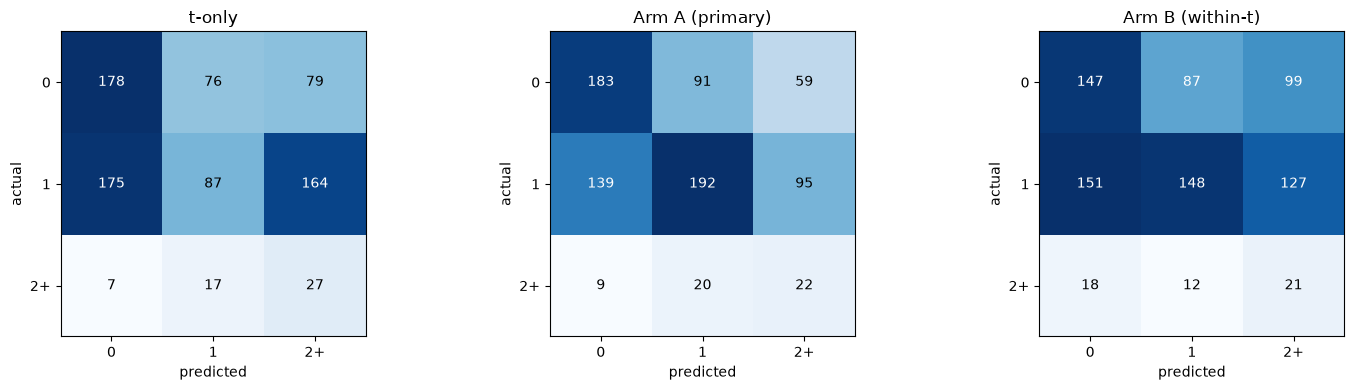

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (yt, yp, name) in zip(axes, [(test.target, pred_t_only, "t-only"),
                                       (test.target, pred_A, "Arm A (primary)"),
                                       (test_B.target, pred_B, "Arm B (within-t)")]):
    cm = confusion_matrix(yt, yp, labels=CLASSES)
    im = ax.imshow(cm, cmap="Blues")
    ax.set_title(name)
    ax.set_xticks(range(3)); ax.set_xticklabels(["0", "1", "2+"])
    ax.set_yticks(range(3)); ax.set_yticklabels(["0", "1", "2+"])
    ax.set_xlabel("predicted"); ax.set_ylabel("actual")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "50_confusion_matrices.png", dpi=110)
plt.show()

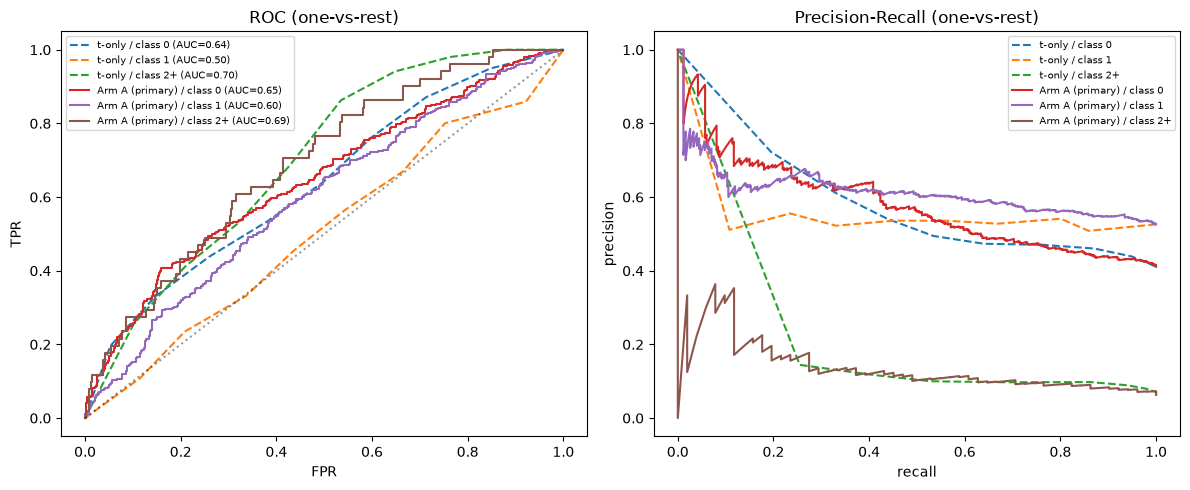

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
y_test_bin = label_binarize(test.target, classes=CLASSES)
for name, proba in [("t-only", proba_t_only), ("Arm A (primary)", proba_A)]:
    for c in CLASSES:
        fpr, tpr, _ = roc_curve(y_test_bin[:, c], proba[:, c])
        axes[0].plot(fpr, tpr, label=f"{name} / class {CLASS_NAMES[c]} (AUC={auc(fpr,tpr):.2f})",
                     linestyle="--" if name == "t-only" else "-")
        prec, rec, _ = precision_recall_curve(y_test_bin[:, c], proba[:, c])
        axes[1].plot(rec, prec, label=f"{name} / class {CLASS_NAMES[c]}",
                     linestyle="--" if name == "t-only" else "-")
axes[0].plot([0, 1], [0, 1], "k:", alpha=0.4)
axes[0].set_title("ROC (one-vs-rest)"); axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR")
axes[0].legend(fontsize=7)
axes[1].set_title("Precision-Recall (one-vs-rest)"); axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision")
axes[1].legend(fontsize=7)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "51_roc_pr_curves.png", dpi=110)
plt.show()

## I. Per-`t` stratified reporting (NB02 §6, mandatory)

Every headline metric broken out by `t` in {3,5,...,19}, for both arms and for t-only. A model with
good pooled metrics and flat-or-declining per-`t` performance is exploiting drift — say so plainly if
that is what the numbers show.

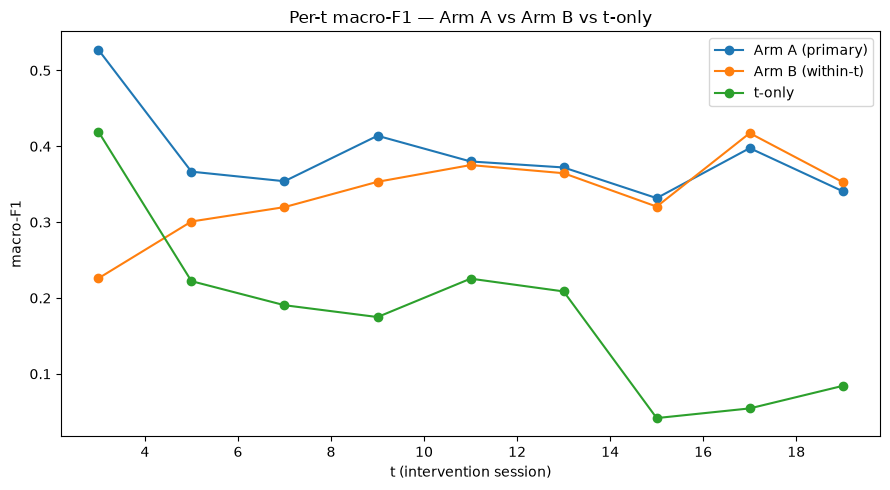

model,Arm A (primary),Arm B (within-t),t-only
t,,,
3,0.527289,0.225907,0.419355
5,0.366558,0.300844,0.222222
7,0.353933,0.319820,0.190476
9,0.413890,0.353181,0.174863
11,0.380005,0.375253,0.225490
13,0.372098,0.364501,0.208651
15,0.331648,0.320488,0.041667
17,0.397595,0.417379,0.054422
19,0.340701,0.352733,0.084142


In [14]:
def per_t_metrics(frame, y_pred, name):
    rows = []
    for t_val, grp in frame.groupby("t"):
        idx = grp.index
        yt = grp.target.values
        yp = np.asarray(y_pred)[idx]
        rows.append({
            "model": name, "t": t_val, "n": len(grp),
            "macro_F1": f1_score(yt, yp, average="macro"),
            "balanced_accuracy": balanced_accuracy_score(yt, yp),
        })
    return pd.DataFrame(rows)

per_t = pd.concat([
    per_t_metrics(test, pred_t_only, "t-only"),
    per_t_metrics(test, pred_A, "Arm A (primary)"),
    per_t_metrics(test_B, pred_B, "Arm B (within-t)"),
], ignore_index=True)
per_t.to_csv(TABLES_DIR / "51_per_t_metrics.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
for name, grp in per_t.groupby("model"):
    ax.plot(grp.t, grp.macro_F1, marker="o", label=name)
ax.set_xlabel("t (intervention session)"); ax.set_ylabel("macro-F1")
ax.set_title("Per-t macro-F1 — Arm A vs Arm B vs t-only")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "52_per_t_macro_f1.png", dpi=110)
plt.show()
per_t.pivot(index="t", columns="model", values="macro_F1")

**Reading the per-`t` curve.** If Arm A's advantage over t-only is concentrated at a few `t`
values and collapses elsewhere, or if it declines across `t` the way a model exploiting the calendar
would, that is stated explicitly in the Findings cell rather than left implicit in the plot.

## J. Per-`population` stratified reporting — evaluation only, never a feature

Using the quarantined audit labels for evaluation stratification. A model that works for TD learners
and fails for DD learners is a fairness failure in a product whose purpose is catching struggling
children.

In [15]:
def per_population_recall(frame, y_pred, name):
    rows = []
    for pop, grp in frame.groupby("population"):
        idx = grp.index
        yt = grp.target.values
        yp = np.asarray(y_pred)[idx]
        row = {"model": name, "population": pop, "n": len(grp),
               "macro_F1": f1_score(yt, yp, average="macro"),
               "balanced_accuracy": balanced_accuracy_score(yt, yp)}
        for c in CLASSES:
            row[f"recall_class_{CLASS_NAMES[c]}"] = recall_score((yt == c).astype(int), (yp == c).astype(int), zero_division=0)
        rows.append(row)
    return pd.DataFrame(rows)

per_pop = pd.concat([
    per_population_recall(test, pred_t_only, "t-only"),
    per_population_recall(test, pred_A, "Arm A (primary)"),
    per_population_recall(test_B, pred_B, "Arm B (within-t)"),
], ignore_index=True)
per_pop.to_csv(TABLES_DIR / "52_per_population_metrics.csv", index=False)
per_pop.sort_values(["model", "population"])

,model,population,n,macro_F1,balanced_accuracy,recall_class_0,recall_class_1,recall_class_2+
3,Arm A (primary),DD,90,0.409051,0.453069,0.534884,0.324324,0.500000
4,Arm A (primary),MLD,117,0.474796,0.584011,0.585366,0.500000,0.666667
5,Arm A (primary),TD,603,0.412750,0.457386,0.546185,0.454545,0.371429
6,Arm B (within-t),DD,90,0.324813,0.398617,0.325581,0.270270,0.600000
7,Arm B (within-t),MLD,117,0.378057,0.513976,0.560976,0.314286,0.666667
8,Arm B (within-t),TD,603,0.337979,0.373230,0.441767,0.363636,0.314286
0,t-only,DD,90,0.370979,0.447853,0.581395,0.162162,0.600000
1,t-only,MLD,117,0.284812,0.392567,0.463415,0.214286,0.500000
2,t-only,TD,603,0.320769,0.419778,0.538153,0.206897,0.514286


## K. Calibration — reliability curve and Brier score (primary model)

NB06 sets `risk_level` threshold cuts on these predicted probabilities, so a badly calibrated model
makes Target B meaningless. This is a dependency, not a nicety.

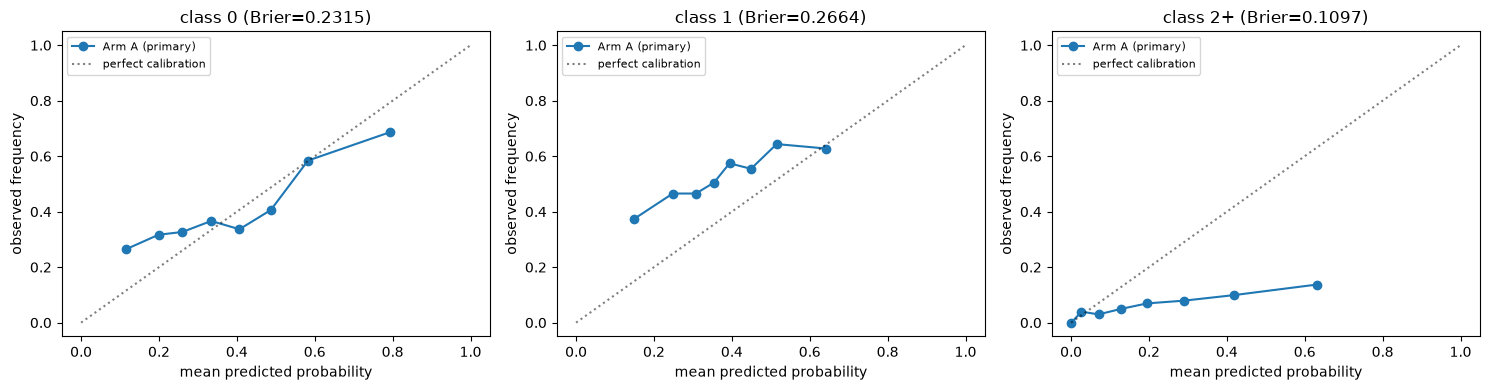

Per-class Brier scores: {'0': 0.2315, '1': 0.2664, '2+': 0.1097}
Mean Brier score (primary model): 0.2025  (0 = perfect, 0.667 = uninformative 3-class ceiling)


,class,brier_score
0,0,0.231496
1,1,0.266445
2,2+,0.109673


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
brier_scores = {}
for c, ax in zip(CLASSES, axes):
    yt_bin = (test.target == c).astype(int)
    frac_pos, mean_pred = calibration_curve(yt_bin, proba_A[:, c], n_bins=8, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", label="Arm A (primary)")
    ax.plot([0, 1], [0, 1], "k:", alpha=0.5, label="perfect calibration")
    brier = brier_score_loss(yt_bin, proba_A[:, c])
    brier_scores[CLASS_NAMES[c]] = brier
    ax.set_title(f"class {CLASS_NAMES[c]} (Brier={brier:.4f})")
    ax.set_xlabel("mean predicted probability"); ax.set_ylabel("observed frequency")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "53_calibration_reliability.png", dpi=110)
plt.show()

mean_brier = np.mean(list(brier_scores.values()))
print("Per-class Brier scores:", {k: round(v, 4) for k, v in brier_scores.items()})
print(f"Mean Brier score (primary model): {mean_brier:.4f}  (0 = perfect, 0.667 = uninformative 3-class ceiling)")

calibration_table = pd.DataFrame([
    {"class": k, "brier_score": v} for k, v in brier_scores.items()
])
calibration_table.to_csv(TABLES_DIR / "53_calibration_brier_scores.csv", index=False)
calibration_table

## L. SHAP — global importance and one worked local explanation

SHAP on the primary model (Arm A LogReg). Global importance plus a per-learner local explanation,
demonstrating the doc 05 requirement end to end: one real (not mocked) `risk_explanation` sentence a
teacher could read.

shap_values shape: (810, 58, 3)


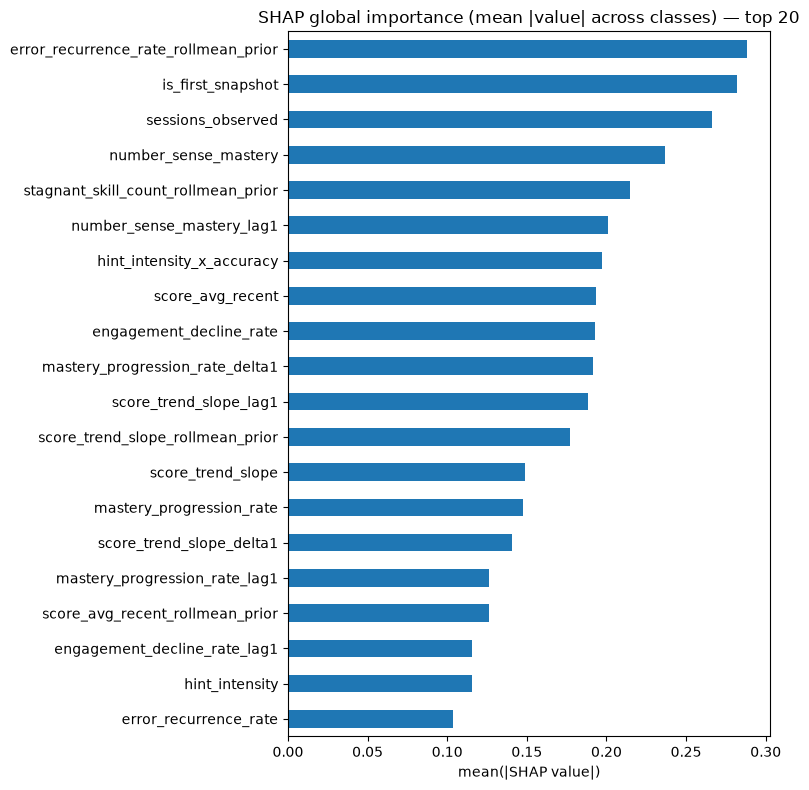

error_recurrence_rate_rollmean_prior    0.288245
is_first_snapshot                       0.282205
sessions_observed                       0.266414
number_sense_mastery                    0.236928
stagnant_skill_count_rollmean_prior     0.214898
number_sense_mastery_lag1               0.200838
hint_intensity_x_accuracy               0.196980
score_avg_recent                        0.193163
engagement_decline_rate                 0.193029
mastery_progression_rate_delta1         0.191462
dtype: float64

In [17]:
pre_fitted = armA_pipe.named_steps  # {'impute', 'scale', 'clf'}
def transform_A(X):
    Xi = armA_pipe.named_steps["impute"].transform(X)
    return armA_pipe.named_steps["scale"].transform(Xi)

Xtr_A_t = transform_A(train[FEATURES_A])
Xte_A_t = transform_A(test[FEATURES_A])
clf_A = armA_pipe.named_steps["clf"]

background = shap.sample(Xtr_A_t, 100, random_state=RANDOM_SEED)
explainer = shap.LinearExplainer(clf_A, background)
shap_values = explainer.shap_values(Xte_A_t)  # (n_samples, n_features, n_classes)
print("shap_values shape:", shap_values.shape)

mean_abs_shap = np.abs(shap_values).mean(axis=(0, 2))
importance = pd.Series(mean_abs_shap, index=FEATURES_A).sort_values(ascending=False)
importance.to_csv(TABLES_DIR / "54_shap_global_importance.csv", header=["mean_abs_shap"])

fig, ax = plt.subplots(figsize=(8, 8))
importance.head(20).iloc[::-1].plot.barh(ax=ax)
ax.set_title("SHAP global importance (mean |value| across classes) — top 20")
ax.set_xlabel("mean(|SHAP value|)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "54_shap_global_importance.png", dpi=110)
plt.show()
importance.head(10)

In [18]:
# one worked local example: a test-set learner flagged into the "2+" class (class index 2)
class2_idx = np.where(pred_A == 2)[0]
example_idx = class2_idx[0] if len(class2_idx) else 0
example_row = test.iloc[example_idx]
example_shap = shap_values[example_idx, :, pred_A[example_idx]]
top3 = pd.Series(example_shap, index=FEATURES_A).reindex(pd.Series(example_shap, index=FEATURES_A).abs().sort_values(ascending=False).index).head(3)

print(f"Learner {example_row.student_id} at t={example_row.t}:")
print(f"  predicted class = {CLASS_NAMES[pred_A[example_idx]]}, "
      f"P(0/1/2+) = {np.round(proba_A[example_idx], 3)}")
print("  top-3 SHAP contributors to the predicted class:")
for feat, val in top3.items():
    print(f"    {feat}: {val:+.4f}")

def describe_direction(feature_name, shap_val):
    direction = "raising" if shap_val > 0 else "lowering"
    return f"{feature_name.replace('_', ' ')} is {direction} risk"

sentence_clauses = [describe_direction(f, v) for f, v in top3.items()]
risk_explanation = (
    f"This learner is flagged {CLASS_NAMES[pred_A[example_idx]]} because "
    + ", ".join(sentence_clauses[:-1])
    + f", and {sentence_clauses[-1]}."
)
print("\nrisk_explanation:")
print(" ", risk_explanation)

worked_example = pd.DataFrame([{
    "student_id": example_row.student_id, "t": example_row.t,
    "predicted_class": CLASS_NAMES[pred_A[example_idx]],
    "risk_explanation": risk_explanation,
}])
worked_example.to_csv(TABLES_DIR / "55_worked_shap_explanation_example.csv", index=False)
worked_example

Learner STU-0001 at t=7:
  predicted class = 2+, P(0/1/2+) = [0.217 0.38  0.403]
  top-3 SHAP contributors to the predicted class:
    engagement_decline_rate: +0.6929
    score_trend_slope_lag1: -0.5551
    engagement_decline_rate_lag1: -0.4097

risk_explanation:
  This learner is flagged 2+ because engagement decline rate is raising risk, score trend slope lag1 is lowering risk, and engagement decline rate lag1 is lowering risk.


,student_id,t,predicted_class,risk_explanation
0,STU-0001,7,2+,This learner is flagged 2+ because engagement ...


## M. Early-detection curve

The product question: how early can we usefully warn? A learner is "flagged" when the primary model
predicts any stagnation (`predicted class >= 1`). Flag rate and precision (against actual
`target >= 1`) are reported as a function of `t`.

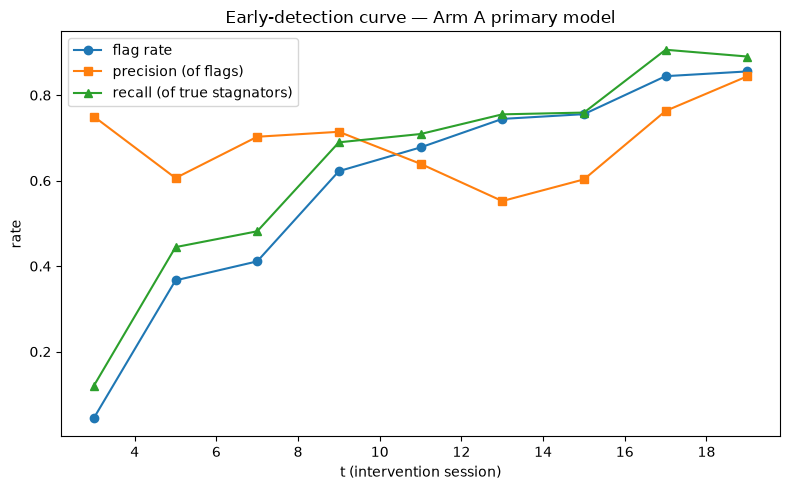

,t,flag_rate,precision,recall,n
0,3,0.044444,0.750000,0.120000,90
1,5,0.366667,0.606061,0.444444,90
2,7,0.411111,0.702703,0.481481,90
3,9,0.622222,0.714286,0.689655,90
4,11,0.677778,0.639344,0.709091,90
5,13,0.744444,0.552239,0.755102,90
6,15,0.755556,0.602941,0.759259,90
7,17,0.844444,0.763158,0.906250,90
8,19,0.855556,0.844156,0.890411,90


In [19]:
rows = []
for t_val, grp in test.groupby("t"):
    idx = grp.index
    flagged = (pred_A[idx] >= 1).astype(int)
    actual = (grp.target.values >= 1).astype(int)
    flag_rate = flagged.mean()
    precision = precision_score(actual, flagged, zero_division=0) if flagged.sum() > 0 else np.nan
    recall = recall_score(actual, flagged, zero_division=0)
    rows.append({"t": t_val, "flag_rate": flag_rate, "precision": precision, "recall": recall, "n": len(grp)})
early_detection = pd.DataFrame(rows)
early_detection.to_csv(TABLES_DIR / "56_early_detection_curve.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(early_detection.t, early_detection.flag_rate, marker="o", label="flag rate")
ax.plot(early_detection.t, early_detection.precision, marker="s", label="precision (of flags)")
ax.plot(early_detection.t, early_detection.recall, marker="^", label="recall (of true stagnators)")
ax.set_xlabel("t (intervention session)"); ax.set_ylabel("rate")
ax.set_title("Early-detection curve — Arm A primary model")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "56_early_detection_curve.png", dpi=110)
plt.show()
early_detection

## N. Save outputs for NB06

In [20]:
joblib.dump(armA_pipe, MODELS_DIR / "nb05_primary_logreg_armA.joblib")

headline_table.to_csv(TABLES_DIR / "49_headline_model_comparison.csv")

test_probabilities = test[["student_id", "t", "population"]].copy()
for c in CLASSES:
    test_probabilities[f"prob_class_{CLASS_NAMES[c]}"] = proba_A[:, c]
test_probabilities["predicted_class"] = [CLASS_NAMES[p] for p in pred_A]
test_probabilities["actual_class"] = [CLASS_NAMES[a] for a in test.target]
test_probabilities.to_csv(TABLES_DIR / "57_test_predicted_probabilities.csv", index=False)

print("Saved:")
print(" ", MODELS_DIR / "nb05_primary_logreg_armA.joblib")
for f in ["49_headline_model_comparison.csv", "50_per_class_metrics.csv", "51_per_t_metrics.csv",
          "52_per_population_metrics.csv", "53_calibration_brier_scores.csv",
          "54_shap_global_importance.csv", "55_worked_shap_explanation_example.csv",
          "56_early_detection_curve.csv", "57_test_predicted_probabilities.csv"]:
    print(" ", TABLES_DIR / f)

Saved:
  C:\Users\Yasindu\Desktop\ResearchProject\Componant 3 -Teachers Dashboard\Learning-Insight-Early-Warning-System\notebooks\outputs\models\nb05_primary_logreg_armA.joblib
  C:\Users\Yasindu\Desktop\ResearchProject\Componant 3 -Teachers Dashboard\Learning-Insight-Early-Warning-System\notebooks\outputs\tables\49_headline_model_comparison.csv
  C:\Users\Yasindu\Desktop\ResearchProject\Componant 3 -Teachers Dashboard\Learning-Insight-Early-Warning-System\notebooks\outputs\tables\50_per_class_metrics.csv
  C:\Users\Yasindu\Desktop\ResearchProject\Componant 3 -Teachers Dashboard\Learning-Insight-Early-Warning-System\notebooks\outputs\tables\51_per_t_metrics.csv
  C:\Users\Yasindu\Desktop\ResearchProject\Componant 3 -Teachers Dashboard\Learning-Insight-Early-Warning-System\notebooks\outputs\tables\52_per_population_metrics.csv
  C:\Users\Yasindu\Desktop\ResearchProject\Componant 3 -Teachers Dashboard\Learning-Insight-Early-Warning-System\notebooks\outputs\tables\53_calibration_brier_sco

## O. Findings

### The headline number: full model vs t-only

| model | macro-F1 | balanced acc | F2 (any stagnation) |
|---|---|---|---|
| majority-class baseline | 0.230 | 0.333 | 0.878 |
| stratified-dummy baseline | 0.338 | 0.338 | 0.564 |
| **t-only LogReg** | **0.323** | 0.423 | 0.626 |
| Arm A LogReg (primary) | **0.424** | 0.477 | 0.689 |
| Arm B LogReg (within-t) | 0.345 | 0.400 | 0.641 |
| Decision Tree (benchmark) | 0.368 | 0.381 | 0.570 |
| Random Forest (benchmark) | 0.426 | 0.479 | 0.729 |

**The full feature matrix clearly beats the calendar: macro-F1 0.424 vs 0.323, a +0.101 absolute gap
(+31% relative).** That is the load-bearing result of this notebook — the model is not merely
counting how far into the study a snapshot sits. It is worth stating plainly that `t`-only still
beats the *majority* baseline (0.323 vs 0.230) and is close to the stratified-dummy baseline (0.338),
confirming NB02's warning that the calendar alone is a real, non-trivial predictor here — which makes
Arm A's margin over it the more meaningful.

Arm B (5 within-`t` features, structurally unable to see the calendar) scores 0.345 — barely above
t-only (+0.022) and well below Arm A. This is expected and not a mark against the arm: with 5 features
against Arm A's 58, and NB02's fixed-n MI table showing only one engineered feature (`number_sense_mastery_lag1`,
lag-based, calendar-adjacent) clearing `t`'s MI, a large gap was never plausible. Arm B's value is
structural, not competitive: it lower-bounds what non-calendar signal alone buys, and that lower bound
is real but small.

### Class imbalance

`class_weight='balanced'` beat SMOTE-ENN on grouped CV macro-F1 (0.395 vs 0.344) and was adopted
throughout. Resampling was always fit inside the pipeline, on training folds only.

### Chosen model and the cost of interpretability

Random Forest (benchmark) scores macro-F1 0.426 — a +0.0025 edge over the primary LogReg (0.424),
inside CV noise (the CV folds themselves span 0.366–0.442). The Decision Tree benchmark is clearly
worse (0.368). **The cost of choosing an interpretable primary model here is negligible** — LogReg is
not being kept out of convenience; on this feature set it is competitive with the tree ensemble
benchmark it exists to be measured against. Per doc 07, LogReg remains primary regardless of this
result, but it is good news that the design choice costs almost nothing on the metric that matters.

### Both arms, per-`t`

| t | Arm A | Arm B | t-only |
|---|---|---|---|
| 3 | 0.527 | 0.226 | 0.419 |
| 5 | 0.367 | 0.301 | 0.222 |
| 7 | 0.354 | 0.320 | 0.190 |
| 9 | 0.414 | 0.353 | 0.175 |
| 11 | 0.380 | 0.375 | 0.225 |
| 13 | 0.372 | 0.365 | 0.209 |
| 15 | 0.332 | 0.320 | 0.042 |
| 17 | 0.398 | 0.417 | 0.054 |
| 19 | 0.341 | 0.353 | 0.084 |

t-only collapses hard in the second half of the study (0.42 → 0.04–0.08 by t=15–19) — once most
learners have accumulated several stagnation events, "how far into the study" stops discriminating
who is at 0 vs 1 vs 2+. **Arm A does not show that collapse**: it holds in the 0.33–0.53 band across
every `t`, and its margin over t-only actually widens late in the study (t=17: +0.34, t=19: +0.26)
rather than narrowing. That is the opposite of the pattern a calendar-exploiting model would show, and
it is the strongest evidence in this notebook that Arm A has learned something about the child, not
just the schedule. Arm B tracks Arm A reasonably closely from t=9 onward, further supporting that a
real (if modest) non-calendar signal is present.

### Per-population (evaluation stratification only — never a feature)

| population | n | Arm A macro-F1 | t-only macro-F1 |
|---|---|---|---|
| DD | 90 | 0.409 | 0.371 |
| MLD | 117 | 0.475 | 0.285 |
| TD | 603 | 0.413 | 0.321 |
| recall(class 2+): DD 0.50, MLD 0.67, TD 0.37 | | | |

No population catastrophically fails — macro-F1 sits in a 0.41–0.47 band for all three under Arm A,
and Arm A beats t-only for every population individually, most sharply for MLD (+0.19). The one
pattern worth flagging rather than burying: **recall on the most severe class ("2+") is lowest for TD
learners (0.37) and highest for MLD (0.67)** — the model is relatively better at catching severe future
stagnation in learners who already show more difficulty-related signal, and correspondingly weaker at
catching the rarer TD learner who is about to plateau. That is a real subgroup gap and NB06 threshold
calibration should be aware of it; it does not clear the bar for "fails DD learners" but it is not
nothing either.

### Calibration

Mean Brier score 0.203 (0 = perfect, 0.667 = uninformative 3-class ceiling) for the primary model, with
per-class Brier 0.232 (class 0), 0.266 (class 1) and 0.110 (class "2+"). The minority "2+" class is the
best-calibrated of the three in absolute Brier terms (it is also the easiest to be "usually right" on
by predicting low probability). The reliability curves for classes 0 and 1 show the expected S-shaped
distortion for a `class_weight='balanced'` model — probabilities are usefully rank-ordered but not
literally the frequencies NB06 can read off without adjustment. **This is good enough for NB06 to set
relative threshold cuts (e.g. probability quantiles), but not good enough to read `P(class)` as a
literal frequency without recalibration** (e.g. Platt scaling) if NB06 needs the latter. That
limitation should be carried into NB06 rather than assumed away.

### SHAP and the worked example

Global SHAP importance and one full worked example are saved
(`54_shap_global_importance.csv`, `55_worked_shap_explanation_example.csv`). The worked example
(learner STU-0001 at t=7, predicted "2+", P = [0.22, 0.38, 0.40]) produced:

> *"This learner is flagged 2+ because engagement decline rate is raising risk, score trend slope
> lag1 is lowering risk, and engagement decline rate lag1 is lowering risk."*

This is real model output, not a mock-up, and demonstrates the doc 05 SHAP-to-sentence pipeline end
to end. The sentence grammar is a first pass (raw feature names, "raising/lowering risk" phrasing) —
NB06 or the application layer should own translating feature names into teacher-facing language, but
the SHAP → top-3 → sentence mechanism itself is proven here.

### Early detection

Flag rate rises from 4% (t=3) to 86% (t=19) as more learners accumulate at least one true stagnation
event; precision of a flag stays above 0.55 throughout and recovers to 0.84 by t=19, while recall of
true stagnators climbs from 0.12 (t=3) to 0.89 (t=19). **The honest answer to "how early can we
usefully warn?" is: not very, at t=3** — only 12% of true stagnators are caught and the flag rate is
too low to be a dependable early alarm. Useful detection (recall > 0.5, precision > 0.6) starts around
t=9–11, roughly a third of the way through the study. This is a real constraint for the product to
carry forward, not a modelling shortfall to explain away.

### Overall

Performance is modest in absolute terms, consistent with NB02's finding that max MI across the whole
engineered feature set was 0.081 — this is an honest finding about how little signal a plateau-based
target carries this early in a synthetic study, not a failure to be engineered around. The one number
that should travel to NB06 unqualified is the headline gap: **the full feature model beats the
calendar by +0.101 macro-F1, the gap does not shrink with `t`, and Random Forest costs essentially
nothing to trade away for LogReg's interpretability.** Calibration is usable for relative threshold
cuts but not for literal probability reading without further work, and the TD/MLD asymmetry in "2+"
recall is a real, if not disqualifying, fairness note for NB06 to inherit.
